In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

RAIZ = Path.cwd()
if not (RAIZ / 'dados_sensores_vulcantech.csv').exists():
    RAIZ = RAIZ.parent
ARQUIVO_CSV = RAIZ / 'dados_sensores_vulcantech.csv'
PASTA_SAIDA = RAIZ / 'dados_processados'
PASTA_SAIDA.mkdir(exist_ok=True)
print(f'Projeto: {RAIZ}')
print(f'CSV encontrado: {ARQUIVO_CSV.exists()}')

SENSORES = [
    'temperatura_fuso_c', 'vibracao_triaxial_rms_mms',
    'torque_fuso_nm', 'vazao_refrigerante_lmin',
    'corrente_estator_amp', 'pressao_hidraulica_bar', 'nivel_ruido_db'
]
dados = pd.read_csv(ARQUIVO_CSV, parse_dates=['timestamp'])
print(f'Linhas carregadas: {len(dados):,}')
display(dados.head())


Projeto: c:\Users\gabriel_silva206\Documents\GitHub\Silvanogbr\VulcanTech_Smart_Metals
CSV encontrado: True
Linhas carregadas: 10,000


,timestamp,id_celula,liga_metalica,temperatura_fuso_c,vibracao_triaxial_rms_mms,torque_fuso_nm,vazao_refrigerante_lmin,corrente_estator_amp,pressao_hidraulica_bar,nivel_ruido_db,tipo_falha
0,2026-10-01 00:00:00,CEL-202,Aco_Carbono_316L,56.04,NaN,95.68,26.31,23.73,168.79,53.96,0
1,2026-10-01 00:05:00,CEL-203,Aco_Carbono_316L,50.76,1.93,118.89,29.97,28.31,144.27,53.43,0
2,2026-10-01 00:10:00,CEL-203,Aco_Carbono_316L,54.95,2.09,96.19,29.16,36.11,159.42,54.23,0
3,2026-10-01 00:15:00,CEL-201,Aco_Carbono_316L,58.18,1.90,101.89,29.31,27.77,162.28,52.93,0
4,2026-10-01 00:20:00,CEL-202,Liga_Titanio_Ti6Al4V,65.81,1.82,132.07,27.21,39.15,147.51,73.67,0


## 1. Análise exploratória

Resumo do conjunto, distribuição dos sensores e tipos de falha. As leituras são exploratórias; os limites usados no tratamento aparecem nas próximas etapas.


Período dos dados: 2026-10-01 00:00:00 até 2026-11-04 17:15:00
Células monitoradas: 4
Ligas metálicas: 3
Registros por tipo de falha:
tipo_falha
0    8557
2     509
1     470
3     464
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
temperatura_fuso_c,9750.0,59.70,68.86,27.71,45.37,52.34,62.53,999.90
vibracao_triaxial_rms_mms,9750.0,1.67,7.26,-99.00,1.54,1.86,2.28,11.28
torque_fuso_nm,10000.0,116.77,30.04,48.84,96.30,111.09,132.43,304.15
vazao_refrigerante_lmin,9800.0,26.65,5.26,-0.09,26.09,27.66,29.15,35.68
corrente_estator_amp,10000.0,29.92,7.95,10.73,24.47,28.50,34.22,74.66
pressao_hidraulica_bar,10000.0,156.23,17.63,-1.00,152.78,158.95,164.68,190.62
nivel_ruido_db,10000.0,57.78,13.15,32.28,48.03,55.28,66.91,122.37


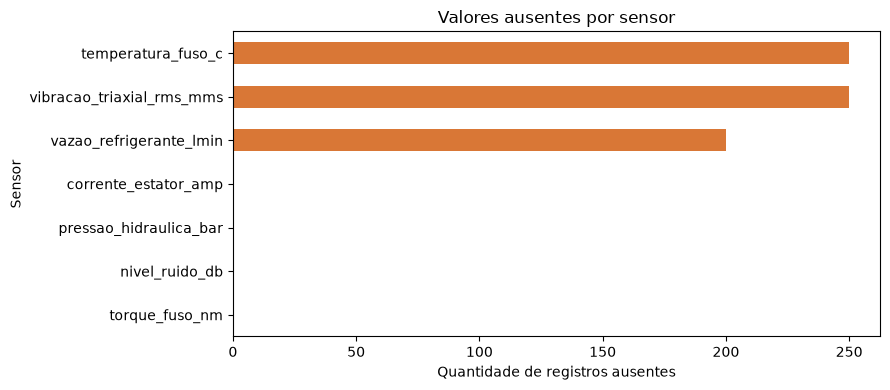

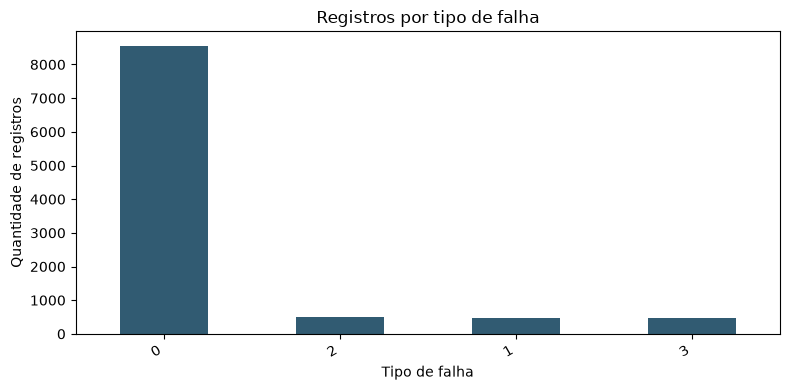

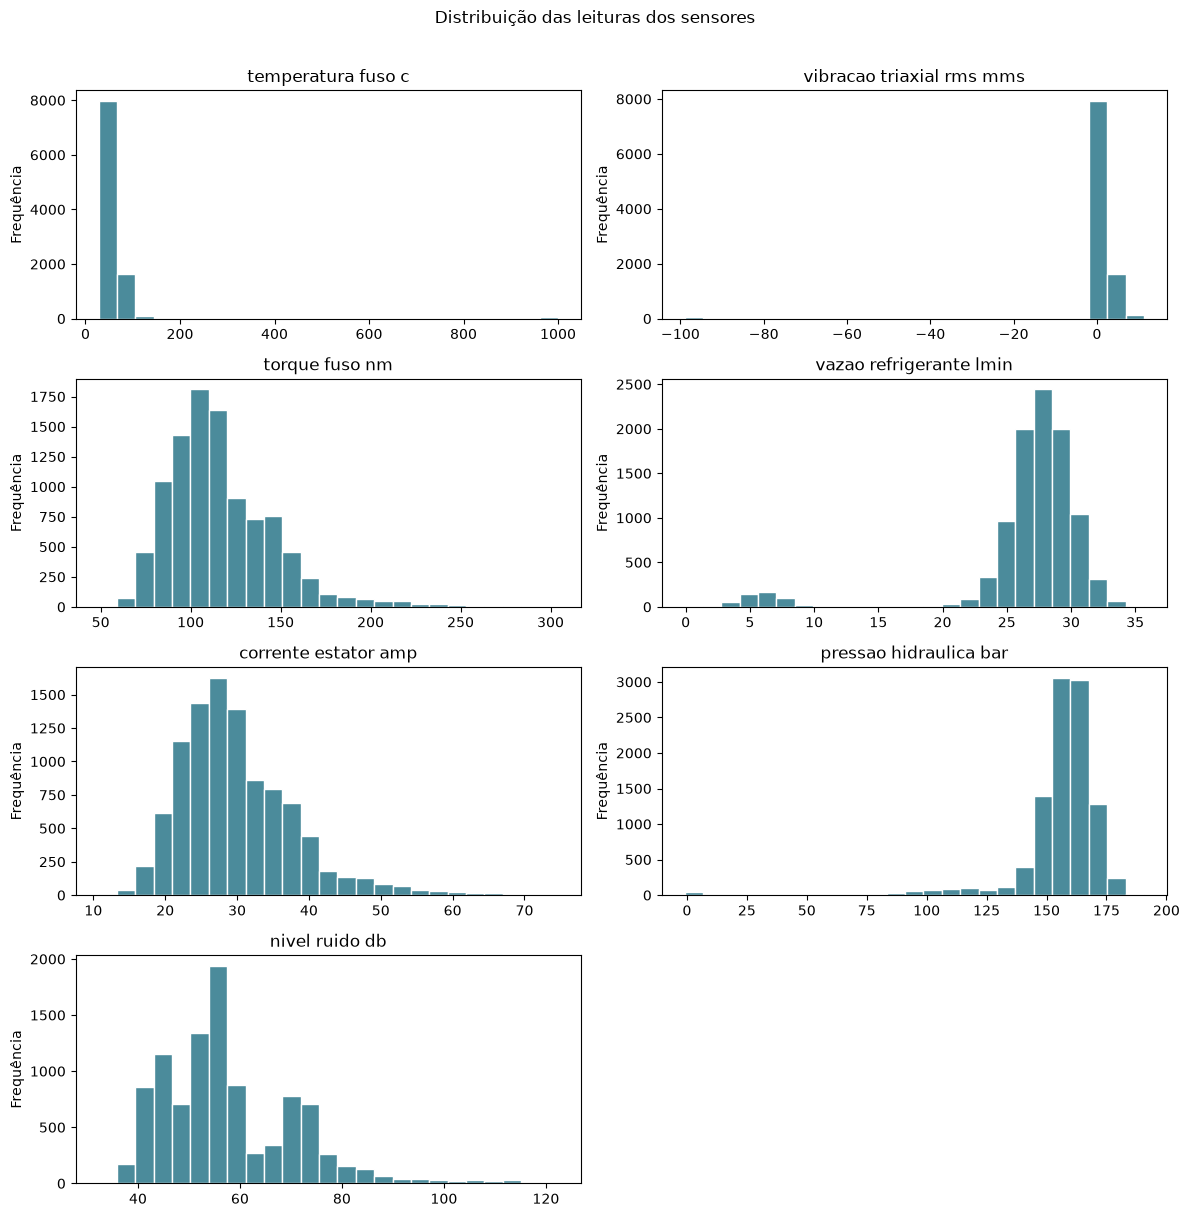

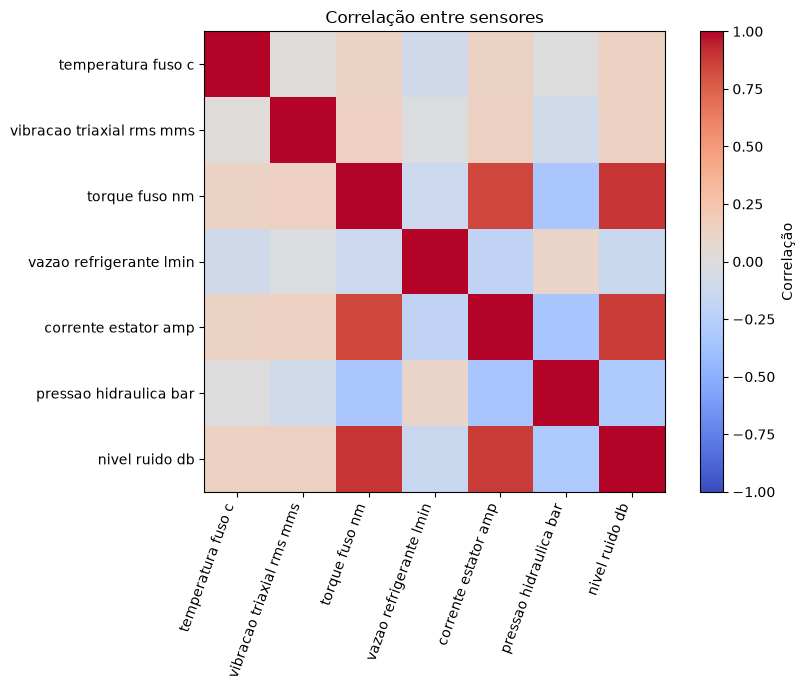

In [2]:
import matplotlib.pyplot as plt
from IPython.display import display

print(f"Período dos dados: {dados['timestamp'].min()} até {dados['timestamp'].max()}")
print(f"Células monitoradas: {dados['id_celula'].nunique()}")
print(f"Ligas metálicas: {dados['liga_metalica'].nunique()}")
print(f"Registros por tipo de falha:\n{dados['tipo_falha'].value_counts(dropna=False)}")

display(dados[SENSORES].describe().T.round(2))

# Valores ausentes por sensor
ax = dados[SENSORES].isna().sum().sort_values().plot(kind='barh', color='#d97736', figsize=(9, 4))
ax.set_title('Valores ausentes por sensor')
ax.set_xlabel('Quantidade de registros ausentes')
ax.set_ylabel('Sensor')
plt.tight_layout()
display(plt.gcf())
plt.close()

# Distribuição das classes registradas no CSV
ax = dados['tipo_falha'].fillna('Sem informação').value_counts().plot(kind='bar', color='#315b72', figsize=(8, 4))
ax.set_title('Registros por tipo de falha')
ax.set_xlabel('Tipo de falha')
ax.set_ylabel('Quantidade de registros')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
display(plt.gcf())
plt.close()

# Distribuições de sensores para comparar escalas e valores típicos
fig, axes = plt.subplots(4, 2, figsize=(12, 12))
for coluna, eixo in zip(SENSORES, axes.flat):
    eixo.hist(dados[coluna].dropna(), bins=25, color='#4b8b9b', edgecolor='white')
    eixo.set_title(coluna.replace('_', ' '))
    eixo.set_ylabel('Frequência')
axes.flat[-1].set_visible(False)
fig.suptitle('Distribuição das leituras dos sensores', y=1.01)
plt.tight_layout()
display(plt.gcf())
plt.close()

# Correlação linear entre os sensores
correlacao = dados[SENSORES].corr()
fig, ax = plt.subplots(figsize=(9, 7))
imagem = ax.imshow(correlacao, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(SENSORES)), [s.replace('_', ' ') for s in SENSORES], rotation=70, ha='right')
ax.set_yticks(range(len(SENSORES)), [s.replace('_', ' ') for s in SENSORES])
ax.set_title('Correlação entre sensores')
fig.colorbar(imagem, ax=ax, label='Correlação')
plt.tight_layout()
display(plt.gcf())
plt.close()


In [3]:
if 'dados' not in globals() or 'SENSORES' not in globals():
    raise RuntimeError('Execute primeiro a célula inicial que carrega o CSV, ou use Run All.')

ausencias_por_grupo = (
    dados.groupby(['id_celula', 'liga_metalica'])[SENSORES]
    .apply(lambda grupo: grupo.isna().mean().mul(100).round(2))
    .reset_index()
)
taxa_ausencia = dados[SENSORES].isna().sum().sum() / (len(dados) * len(SENSORES)) * 100
print(f'Ausências nas colunas de sensores: {taxa_ausencia:.2f}%')
display(ausencias_por_grupo)

Ausências nas colunas de sensores: 1.00%


,id_celula,liga_metalica,temperatura_fuso_c,vibracao_triaxial_rms_mms,torque_fuso_nm,vazao_refrigerante_lmin,corrente_estator_amp,pressao_hidraulica_bar,nivel_ruido_db
0,CEL-201,Aco_Carbono_316L,2.28,2.20,0.0,2.03,0.0,0.0,0.0
1,CEL-201,Aluminio_7075,3.31,1.78,0.0,1.53,0.0,0.0,0.0
2,CEL-201,Liga_Titanio_Ti6Al4V,2.05,2.46,0.0,2.05,0.0,0.0,0.0
3,CEL-202,Aco_Carbono_316L,3.66,2.49,0.0,2.57,0.0,0.0,0.0
4,CEL-202,Aluminio_7075,1.91,2.29,0.0,1.65,0.0,0.0,0.0
5,CEL-202,Liga_Titanio_Ti6Al4V,1.96,2.54,0.0,1.96,0.0,0.0,0.0
6,CEL-203,Aco_Carbono_316L,2.67,3.24,0.0,1.13,0.0,0.0,0.0
7,CEL-203,Aluminio_7075,1.55,2.26,0.0,1.69,0.0,0.0,0.0
8,CEL-203,Liga_Titanio_Ti6Al4V,2.62,2.21,0.0,1.01,0.0,0.0,0.0
9,CEL-204,Aco_Carbono_316L,2.53,2.61,0.0,3.43,0.0,0.0,0.0


In [4]:
LIMITES = {
    'temperatura_fuso_c': (30, 75),
    'vibracao_triaxial_rms_mms': (0.8, 3.8),
    'torque_fuso_nm': (45, 210),
    'vazao_refrigerante_lmin': (15, 40),
    'corrente_estator_amp': (12, 55),
    'pressao_hidraulica_bar': (110, 220),
    'nivel_ruido_db': (45, 85),
}

dados_tratados = dados.sort_values(['id_celula', 'timestamp']).copy()
for coluna, (minimo, maximo) in LIMITES.items():
    fora_faixa = ~dados_tratados[coluna].between(minimo, maximo)
    dados_tratados.loc[fora_faixa, coluna] = np.nan

for coluna in SENSORES:
    media = dados_tratados.groupby('liga_metalica')[coluna].transform('mean')
    desvio = dados_tratados.groupby('liga_metalica')[coluna].transform('std').replace(0, 1)
    z_score = (dados_tratados[coluna] - media) / desvio
    dados_tratados.loc[z_score.abs() > 3, coluna] = np.nan

display(dados_tratados[SENSORES].isna().sum().to_frame('ausências após limites e Z-score'))

,ausências após limites e Z-score
temperatura_fuso_c,1054
vibracao_triaxial_rms_mms,1313
torque_fuso_nm,438
vazao_refrigerante_lmin,756
corrente_estator_amp,363
pressao_hidraulica_bar,463
nivel_ruido_db,2262


In [5]:
dados_tratados = dados_tratados.set_index('timestamp')
for coluna in SENSORES:
    dados_tratados[coluna] = dados_tratados.groupby('id_celula', group_keys=False)[coluna].apply(
        lambda serie: serie.interpolate(method='time', limit=2, limit_area='inside')
    )
dados_tratados = dados_tratados.reset_index().sort_values('timestamp').reset_index(drop=True)

for coluna in SENSORES:
    mediana_celula = dados_tratados.groupby('id_celula')[coluna].transform('median')
    dados_tratados[coluna] = dados_tratados[coluna].fillna(mediana_celula)
    dados_tratados[coluna] = dados_tratados[coluna].fillna(dados_tratados[coluna].median())

print(f'Ausências restantes: {int(dados_tratados[SENSORES].isna().sum().sum())}')

Ausências restantes: 0


In [6]:
for coluna in ['vibracao_triaxial_rms_mms', 'torque_fuso_nm', 'vazao_refrigerante_lmin']:
    nome = coluna.removesuffix('_mms').removesuffix('_nm').removesuffix('_lmin')
    dados_tratados[f'{nome}_media_30min'] = dados_tratados.groupby('id_celula')[coluna].transform(
        lambda serie: serie.rolling(6, min_periods=1).mean()
    )
    dados_tratados[f'{nome}_desvio_2h'] = dados_tratados.groupby('id_celula')[coluna].transform(
        lambda serie: serie.rolling(24, min_periods=2).std()
    ).fillna(0)

dados_tratados['iem'] = (
    dados_tratados['torque_fuso_nm'] * dados_tratados['vibracao_triaxial_rms_mms']
    / (dados_tratados['vazao_refrigerante_lmin'] + 1)
)
for coluna in SENSORES:
    media_liga = dados_tratados.groupby('liga_metalica')[coluna].transform('mean').replace(0, 1)
    dados_tratados[f'{coluna}_normalizado_liga'] = dados_tratados[coluna] / media_liga

display(dados_tratados[['timestamp', 'id_celula', 'liga_metalica', 'iem']].head())

,timestamp,id_celula,liga_metalica,iem
0,2026-10-01 00:00:00,CEL-202,Aco_Carbono_316L,6.271227
1,2026-10-01 00:05:00,CEL-203,Aco_Carbono_316L,7.409031
2,2026-10-01 00:10:00,CEL-203,Aco_Carbono_316L,6.665686
3,2026-10-01 00:15:00,CEL-201,Aco_Carbono_316L,6.387034
4,2026-10-01 00:20:00,CEL-202,Liga_Titanio_Ti6Al4V,8.520645


,Antes do tratamento,Depois do tratamento
temperatura_fuso_c,250,0
vibracao_triaxial_rms_mms,250,0
torque_fuso_nm,0,0
vazao_refrigerante_lmin,200,0
corrente_estator_amp,0,0
pressao_hidraulica_bar,0,0
nivel_ruido_db,0,0


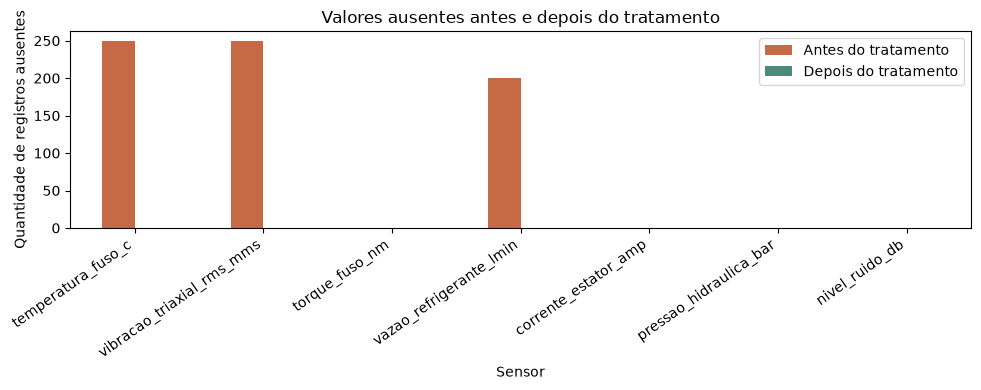

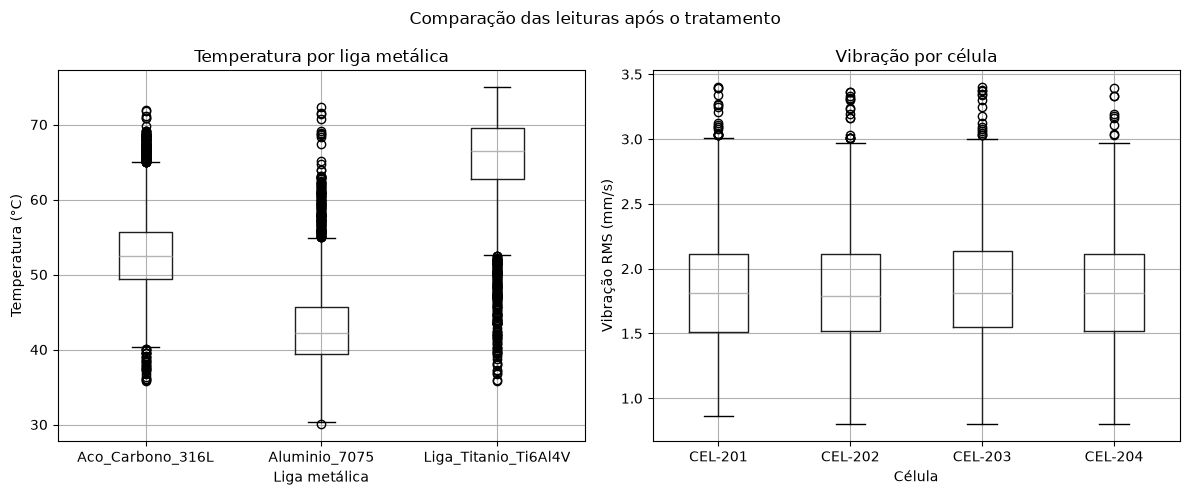

,count,mean,median
tipo_falha,,,
0,8557,7.10,6.54
1,470,9.61,9.33
2,509,10.15,9.56
3,464,8.46,8.15


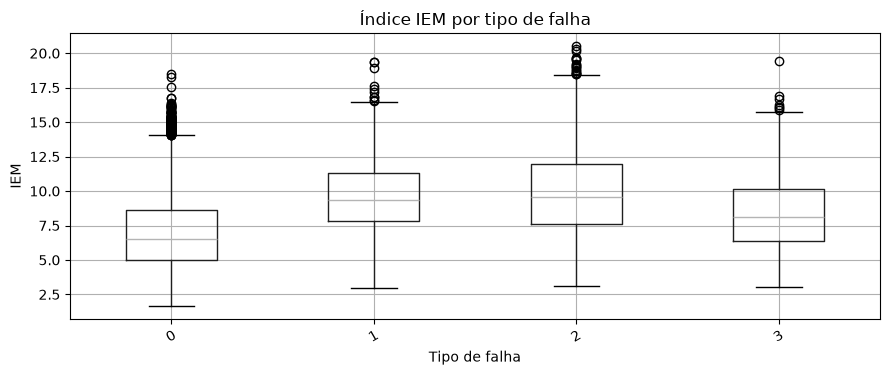

In [7]:
comparacao_ausencias = pd.DataFrame({
    'Antes do tratamento': dados[SENSORES].isna().sum(),
    'Depois do tratamento': dados_tratados[SENSORES].isna().sum()
})
display(comparacao_ausencias)

ax = comparacao_ausencias.plot(kind='bar', figsize=(10, 4), color=['#c56a45', '#4b8b78'])
ax.set_title('Valores ausentes antes e depois do tratamento')
ax.set_xlabel('Sensor')
ax.set_ylabel('Quantidade de registros ausentes')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
display(plt.gcf())
plt.close()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
dados_tratados.boxplot(column='temperatura_fuso_c', by='liga_metalica', ax=axes[0])
axes[0].set_title('Temperatura por liga metálica')
axes[0].set_xlabel('Liga metálica')
axes[0].set_ylabel('Temperatura (°C)')
dados_tratados.boxplot(column='vibracao_triaxial_rms_mms', by='id_celula', ax=axes[1])
axes[1].set_title('Vibração por célula')
axes[1].set_xlabel('Célula')
axes[1].set_ylabel('Vibração RMS (mm/s)')
fig.suptitle('Comparação das leituras após o tratamento')
plt.tight_layout()
display(plt.gcf())
plt.close()

# Relação entre o índice de eficiência/manutenção e os registros de falha
resumo_iem = dados_tratados.groupby('tipo_falha')['iem'].agg(['count', 'mean', 'median']).round(2)
display(resumo_iem)
ax = dados_tratados.boxplot(column='iem', by='tipo_falha', figsize=(9, 4), rot=30)
ax.set_title('Índice IEM por tipo de falha')
ax.set_xlabel('Tipo de falha')
ax.set_ylabel('IEM')
plt.suptitle('')
plt.tight_layout()
display(plt.gcf())
plt.close()


In [8]:
display(dados_tratados[SENSORES + ['iem']].describe().round(2))
display(dados_tratados[SENSORES].isna().sum().to_frame('ausências finais'))

dados_tratados.to_csv(PASTA_SAIDA / 'sensores_preparados.csv', index=False)
ausencias_por_grupo.to_csv(PASTA_SAIDA / 'ausencias_por_celula_liga.csv', index=False)
print(f'Arquivos salvos em: {PASTA_SAIDA}')

,temperatura_fuso_c,vibracao_triaxial_rms_mms,torque_fuso_nm,vazao_refrigerante_lmin,corrente_estator_amp,pressao_hidraulica_bar,nivel_ruido_db,iem
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,52.23,1.84,112.90,27.80,29.07,159.15,58.74,7.44
std,9.51,0.44,23.37,2.06,6.53,8.70,8.52,3.01
min,30.05,0.80,48.84,21.22,12.21,126.51,45.00,1.67
25%,44.98,1.52,95.75,26.43,24.35,153.86,52.96,5.18
50%,51.45,1.81,110.04,27.81,28.27,159.36,56.46,6.85
75%,57.95,2.12,127.99,29.21,33.35,164.93,65.27,9.20
max,74.98,3.40,183.55,33.98,50.74,188.21,82.78,20.50


,ausências finais
temperatura_fuso_c,0
vibracao_triaxial_rms_mms,0
torque_fuso_nm,0
vazao_refrigerante_lmin,0
corrente_estator_amp,0
pressao_hidraulica_bar,0
nivel_ruido_db,0


Arquivos salvos em: c:\Users\gabriel_silva206\Documents\GitHub\Silvanogbr\VulcanTech_Smart_Metals\dados_processados
